N = 3143
Peak at k = 24
Period = N/k = 131.0 months = 10.91 years


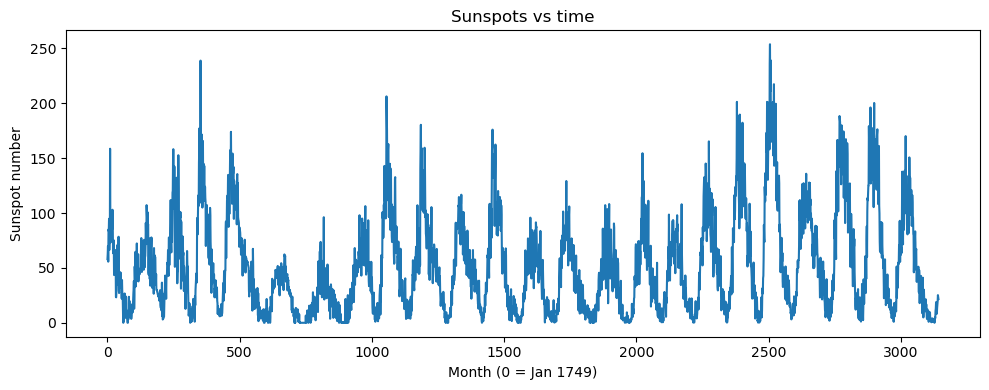

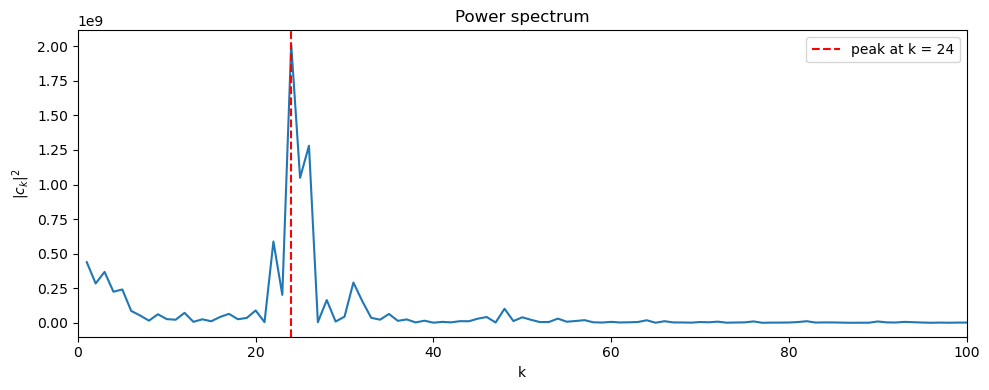

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Load data: column 0 = month index, column 1 = sunspot number
data = np.loadtxt("/Users/nichaeadnan/Desktop/sunspots.txt")
t = data[:, 0]
y = data[:, 1]
N = len(y)

# (a) Plot sunspots vs time
plt.figure(figsize=(10, 4))
plt.plot(t, y)
plt.xlabel("Month (0 = Jan 1749)")
plt.ylabel("Sunspot number")
plt.title("Sunspots vs time")
plt.tight_layout()
plt.savefig("/Users/nichaeadnan/Desktop/sunspots_time.png", dpi=150)

# (b) Fourier transform and power spectrum |c_k|^2
c = np.fft.rfft(y)          # c_k for k = 0..N/2
power = np.abs(c) ** 2

# locate the peak (excluding k = 0, the mean)
k = np.arange(len(power))
kpeak = np.argmax(power[1:]) + 1

plt.figure(figsize=(10, 4))
plt.plot(k[1:], power[1:])  # skip k=0 so the mean doesn't swamp the plot
plt.axvline(kpeak, color="red", linestyle="--", label=f"peak at k = {kpeak}")
plt.xlabel("k")
plt.ylabel(r"$|c_k|^2$")
plt.title("Power spectrum")
plt.xlim(0, 100)
plt.legend()
plt.tight_layout()
plt.savefig("/Users/nichaeadnan/Desktop/sunspots_power.png", dpi=150)

# (c) Convert the peak to a period
period = N / kpeak
print(f"N = {N}")
print(f"Peak at k = {kpeak}")
print(f"Period = N/k = {period:.1f} months = {period/12:.2f} years")

plt.show()